## <center>**Aula Prática Phyton: Testes paramétricos**</center>

Primeiro, é necessário carregar o dataset. Para baixar o dataset e mais informações, acesse: http://archive.ics.uci.edu/ml/datasets/Adult

Este dataset contém informações do Censo Americano e o objetivo dele é predizer se uma determinada pessoa tem ganho maior que 50K em um ano. Essa predição é baseada nas informações sociais coletadas no Censo. Essa situação poderia ser utilizada para obter um empréstimo ou não (se ganha mais de 50K libera o empréstimo).

In [7]:
# importa as bibliotecas
import pandas as pd
import numpy as np

In [8]:
# importa o data set
from google.colab import files
uploaded = files.upload()

# para baixar o dataset, acesse:
# Observação 1: Este dataset já é dividido em treino e teste previamente. Porém, vou usar somente o conjunto de
# teste como sendo o dataset original, pois a maioria dos datasets não são previamentes divididos em conjuntos
# de teste e conjunto de treino (isso é feito no processo de Aprendizado de Máquina)

# do site eu recuperei o nome de cada coluna do data set
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation',
           'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
           'income']

# abro o dataset e nomeio cada coluna com meu vetor columns
data = pd.read_csv('adult.data', names=columns)

# Fazendo a mesma coisa do Google Colab
# from google.colab import drive
# drive.mount('/content/drive')
# data = pd.read_csv('/content/drive/My Drive/EABDA 2020/adult.data', names=columns)

# elimina os espaços no começo e no fim das strings
data = data.applymap(lambda x: x.strip() if isinstance(x, str) else x)

# visualiza a tabela, o método head() mostra as 5 primeiras linhas da tabela
# note que a coluna 'target' é a variável dependente ou resposta (classe).
# o restante das colunas são as variáveis explicativas ou independentes ou preditoras (features, atributos), e cada linha é um indivíduo (instância ou exemplo).
data.head()

Saving adult.data to adult (1).data


<ipython-input-8-612ab1b63e5b>:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  data = data.applymap(lambda x: x.strip() if isinstance(x, str) else x)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [9]:
# mostra o número de linhas (unidades amostrais) e colunas (variáveis)
data.shape

(32561, 15)

Geralmente, os datasets vem com dados faltantes, no caso deste dataset os dados faltantes é simbolizado pelo caractere '?'. Existem diversas estratégias para trabalhar com dados faltantes. Algumas metodologias podem lidar com "missings" sem nenhum problema, mas outras necessitam de dados completos. Nesses casos, pode-se imputar dados. Há formas sofisticadas e simples de imputação. Porém, no nosso caso, por questões didáticas e de simplificação, vou excluir todos os dados faltantes da nossa base de dados.

In [10]:
# elimina as linhas com dados faltantes
# data = pd.DataFrame
# null_symbol = caractere que simboliza que há dados faltantes
def remove_rows(data, null_symbol=np.nan):
    # salva o total de exemplos
    total = len(data)
    # substitui o null_symbol por nulo
    data = data.replace(null_symbol, np.nan)
    # elimina as linhas que contém algum valor nulo
    data.dropna(inplace=True)
    print('Execute: preprocessing_remove_rows\n---Removed %d rows in the table' % (total - len(data)))
    return data

data = remove_rows(data, '?')

Execute: preprocessing_remove_rows
---Removed 2399 rows in the table


In [11]:
# o tamanho atualizado do conjunto de dados
data.shape

(30162, 15)

* ### **Teste para a comparação de 2 proporções: amostras independentes**


In [12]:
# Há injustiça no valor salarial?
c = data["income"].value_counts(sort=False)
p = data["income"].value_counts(normalize=True,sort=False).round(3) * 100
pd.concat([c,p], axis=1, keys=['counts', '%'])


,counts,%
income,,
<=50K,22654,75.1
>50K,7508,24.9


In [ ]:
# Tabela de frequências cruzadas ou tabela de contingência
pd.crosstab(data.sex, data.income,margins=True)

income,<=50K,>50K,All
sex,,,
Female,8670,1112,9782
Male,13984,6396,20380
All,22654,7508,30162


In [ ]:
# Percentual de linhas
pd.crosstab(data.sex, data.income,normalize='index')

income,<=50K,>50K
sex,,
Female,0.886322,0.113678
Male,0.686163,0.313837


* **Teste de qui-quadrado para independência**

In [ ]:
from scipy.stats import chi2_contingency

# teste quiquadrado para independência/homogeneidade de distribuição
obs = pd.crosstab(data.sex, data.income)
chi2_contingency(obs)

Chi2ContingencyResult(statistic=1415.2864042410245, pvalue=1.00155254124934e-309, dof=1, expected_freq=array([[ 7347.04024932,  2434.95975068],
       [15306.95975068,  5073.04024932]]))

* **z teste**

In [ ]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

count = np.array([1112, 6396])
nobs = np.array([9782, 20380])
stat, pval = proportions_ztest(count, nobs)
print("Estatística do teste = ",stat,"p-valor = ",pval)

Estatística do teste =  -37.63451605872578 p-valor =  5.86241470132814e-310


In [ ]:
from scipy.stats import norm

# Qual o valor de Z ~ N(0,1) que deixa 2.5% dos dados à esquerda : F(z)=0,025
z= norm.ppf(0.025)
print("A Região crítica é dada por: z<",z, "ou z>",-z)


A Região crítica é dada por: z< -1.9599639845400545 ou z> 1.9599639845400545


O valor da estatística do teste z é dado por: $\frac{\hat{p_1} - \hat{p_2}}{\sqrt{\hat{p}(1-\hat{p})(1/n_1+1/n_2)}}$

In [ ]:
# Estatística do z teste
estat = (0.113678-0.313837)/np.sqrt(7508/30162*(1-7508/30162)*(1/9782+1/20380))
estat

-37.634532835846585

Para calcular o nível descritivo do teste (p-valor ou valor-p), lembre que a estatística desse teste tem distribuição aproximadamente N(0,1) e que o teste é bicaudal:

In [ ]:
# valor p
2*norm.cdf(estat) # para o teste bicaudal, tem-se que mutiplicar por 2

5.8587117390029e-310



---

No R, o mesmo teste é feito com:

```
count = c(1112, 6396)
nobs = c(9782, 20380)
prop.test(count, nobs, p = NULL, alternative = "two.sided", correct = FALSE)

```






---



* ### **Testes t de Student**

In [14]:
# Há diferença de idade entre os sexos?
dataF = data.loc[data.sex=='Female', "age"]
dataM = data.loc[data.sex=='Male', "age"]

# Uma análise descritiva de idade por grupo (sexo)
data.groupby('sex').agg({'age': ['count',min, max, 'median','mean', 'std']})

<ipython-input-14-7874953af68c>:6: FutureWarning: The provided callable <built-in function min> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  data.groupby('sex').agg({'age': ['count',min, max, 'median','mean', 'std']})
<ipython-input-14-7874953af68c>:6: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  data.groupby('sex').agg({'age': ['count',min, max, 'median','mean', 'std']})


age                                     
        count min max median       mean        std
sex                                               
Female   9782  17  90   35.0  36.883459  13.532427
Male    20380  17  90   38.0  39.184004  12.873243

In [ ]:
from scipy import stats

# Teste t de Student (bicaudal) para média de duas populações Normais com variâncias iguais
stats.ttest_ind(dataF,dataM, equal_var = True)

TtestResult(statistic=-14.287461138797537, pvalue=3.707459425795102e-46, df=30160.0)

In [ ]:
import math

# Cálculo do valor da estatística do teste t de Student para variâncias iguais
(36.883459-39.184004)/math.sqrt((9782*13.532427**2+20380*12.873243**2)/(9782+20380-2)*(1/9782+1/20380))

-14.286982460513402

Vamos verificar as suposições do teste t de Student para variâncias iguais: heterocedasticidae e distribuição Normal:

In [ ]:
# Teste de Levene para igualdade de variâncias
# stats.levene(dataF,dataM)

# Teste de Bartlett para igualdade de variâncias
stats.bartlett(dataF,dataM)


BartlettResult(statistic=33.33814573890982, pvalue=7.74484748741725e-09)

Vamos fazer um exercícios com esses dados para perceber como o tamanho da amostra influencia muito os resultados.

In [24]:
# Selecione uma amostra de 95% e outra de 0,5% e repare como o resultado do teste muda
sampleF=dataF.sample(frac=0.005)
sampleM=dataM.sample(frac=0.005)

# Teste t de Student (bicaudal) para média de duas populações Normais com variâncias iguais
stats.ttest_ind(sampleF,sampleM, equal_var = True)

TtestResult(statistic=0.28214709024029727, pvalue=0.7782222506759274, df=149.0)

Vamos descrever a idade das subamostras selecionadas de homens e mulheres.

In [25]:
sampleF.describe()

,age
count,49.000000
mean,38.204082
std,14.601626
min,18.000000
25%,26.000000
50%,36.000000
75%,50.000000
max,71.000000


In [ ]:
sampleM.describe()

,age
count,102.000000
mean,37.049020
std,12.707196
min,17.000000
25%,27.000000
50%,35.000000
75%,44.750000
max,71.000000


Vamos repetir a verificação das suposições para essas subamostras.

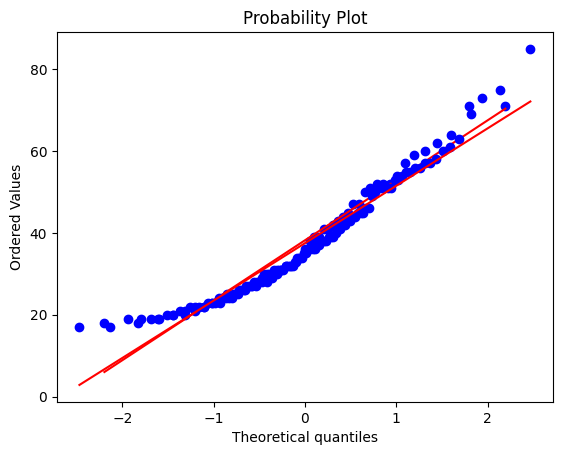

<Figure size 640x480 with 0 Axes>

In [26]:
import matplotlib.pyplot as plt
from scipy import stats

# Gráfico de probabilidade da Normal, para checar suposição de tal distribuição dos dados
# para o teste t de Student
stats.probplot(sampleF, plot=plt)
stats.probplot(sampleM, plot=plt)
fig = plt.figure()

In [27]:
# Teste de Shapiro-Wilks para normalidade
stats.shapiro(dataM)

/usr/local/lib/python3.10/dist-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 20380.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=0.9752719914342175, pvalue=1.5024569931365348e-49)

In [28]:
# Teste de Kolmogorov-Smirnov para normalidade
mu = dataF.mean()
sigma = dataF.std()
stats.kstest(dataF,'norm',args=(mu,sigma))

KstestResult(statistic=0.08001335891281686, pvalue=6.388542982123233e-55, statistic_location=31, statistic_sign=1)

In [29]:
# Teste de Levene para igualdade de variâncias
stats.levene(sampleF,sampleM)


LeveneResult(statistic=0.45708248141267555, pvalue=0.5000386906744021)

* ### **ANOVA**

Inicialmente, importemos o arquivo de dados de músicas do Spotify.

In [31]:
# importa o data set
from google.colab import files
uploaded = files.upload()

data2 = pd.read_excel('Music_DB.xlsx')
data2.head()

Saving Music_DB.xlsx to Music_DB (1).xlsx


,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Tipo,Music_id,Playlist_name,Album_name,Artista,Music_name
0,0.964,0.1060,167.024,0.0644,0.000071,0.038700,4,0.392,10,200547,0.599722,0.269,0,audio_features,0faXHILILebCGnJBPU6KJJ,Angry,Phobia (Clean Version),Breaking Benjamin,The Diary of Jane - Single Version
1,0.955,0.3800,107.984,0.0653,0.000165,0.000014,4,0.533,8,216733,0.652529,0.550,1,audio_features,2yXyz4NLTZx9CLdXfLTp5E,Angry,Dear Agony,Breaking Benjamin,I Will Not Bow
2,0.939,0.6230,150.184,0.1130,0.000220,0.000000,4,0.524,9,184867,0.631393,0.661,1,audio_features,1Vej0qeQ3ioKwpI6FUbRv1,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Papercut
3,0.969,0.0787,95.136,0.0491,0.001400,0.000001,4,0.492,9,157333,0.601243,0.538,1,audio_features,3K4HG9evC7dg3N0R9cYqk4,Angry,Hybrid Theory (Bonus Edition),Linkin Park,One Step Closer
4,0.970,0.0994,94.952,0.2120,0.030000,0.000000,4,0.512,8,200240,0.639293,0.427,0,audio_features,5egqKwgK5r5rvGD1LrtR7J,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Points of Authority


Descrevendo a variável Dançabilidade para todas as Playlists para verificar se algumas têm distribuição similar.

In [35]:
# Agrupar por 'Playlist_name' e calcular o número de músicas, média e desvio padrão de 'Dançabilidade'
playlist_stats = data2.groupby('Playlist_name').agg(
    num_musics=('Dançabilidade', 'count'),
    mean_danceability=('Dançabilidade', 'mean'),
    std_danceability=('Dançabilidade', 'std')
).reset_index()

# Exibir o resultado
print(playlist_stats)

   Playlist_name  num_musics  mean_danceability  std_danceability
0          Angry         535           0.474740          0.112356
1       Annoying         470           0.657787          0.156784
2         Boring         555           0.645300          0.175000
3           Calm         635           0.501232          0.169491
4        Excited         518           0.625670          0.167689
5          Happy         609           0.628447          0.117377
6        Nervous         634           0.550323          0.195301
7       Peaceful         833           0.347715          0.189818
8        Pleased         678           0.595858          0.147819
9        Relaxed         840           0.382625          0.231861
10           Sad         514           0.516133          0.172569
11        Sleepy         881           0.262525          0.150208


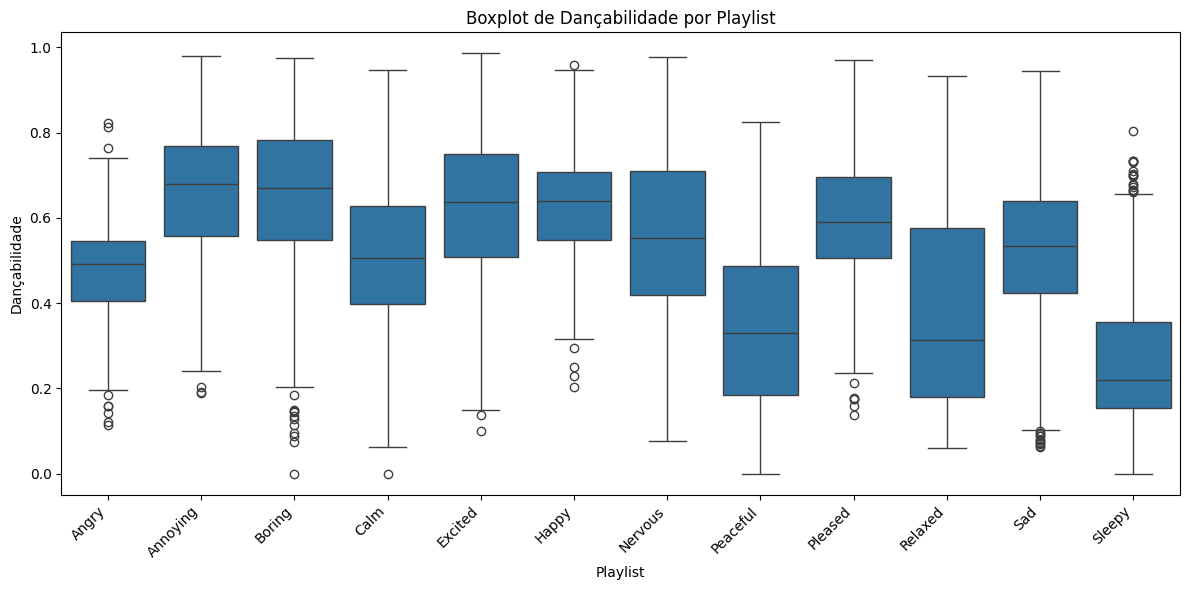

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

# Definir o tamanho da figura
plt.figure(figsize=(12, 6))

# Criar o boxplot
sns.boxplot(x='Playlist_name', y='Dançabilidade', data=data2)

# Rotacionar os rótulos das playlists no eixo x, se necessário
plt.xticks(rotation=45, ha='right')

# Definir o título e os rótulos dos eixos
plt.title('Boxplot de Dançabilidade por Playlist')
plt.xlabel('Playlist')
plt.ylabel('Dançabilidade')

# Exibir o gráfico
plt.tight_layout()
plt.show()

Intuitivamente, algumas Playlists não devem ser muito diferentes entre si. Por exemplo, Angry, Excited, Happy e Nervous podem estar relacionadas a músicas mais rítmicas, com Dançabilidade parecidas, por exemplo. Vamos explorar melhor essa intuição focando nesses 4 estilos.

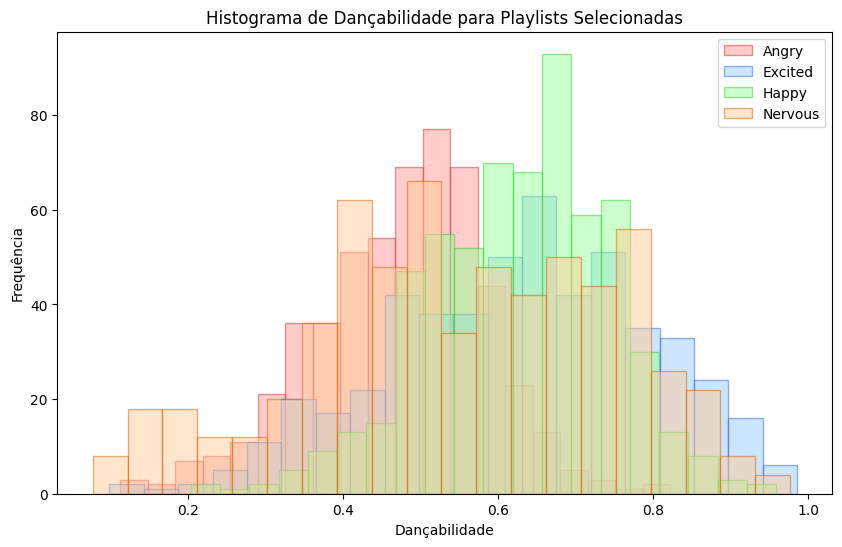

In [41]:
import matplotlib.pyplot as plt

# Filtrar o DataFrame para as playlists desejadas
playlists = ['Angry', 'Excited', 'Happy', 'Nervous']
filtered_data = data2[data2['Playlist_name'].isin(playlists)]

# Definir cores diferentes e levemente transparentes para cada playlist
colors = {
    'Angry': '#FF9999',    # Tom claro de vermelho
    'Excited': '#99CCFF',  # Tom claro de azul
    'Happy': '#99FF99',    # Tom claro de verde
    'Nervous': '#FFCC99'   # Tom claro de laranja
}

# Definir cores das bordas mais escuras
edge_colors = {
    'Angry': '#CC3333',    # Bordas mais escuras para vermelho
    'Excited': '#3366CC',  # Bordas mais escuras para azul
    'Happy': '#33CC33',    # Bordas mais escuras para verde
    'Nervous': '#CC6600'   # Bordas mais escuras para laranja
}

# Definir o tamanho da figura
plt.figure(figsize=(10, 6))

# Criar o histograma para cada playlist
for playlist in playlists:
    subset = filtered_data[filtered_data['Playlist_name'] == playlist]
    plt.hist(subset['Dançabilidade'], bins=20, alpha=0.5, color=colors[playlist], edgecolor=edge_colors[playlist], label=playlist)

# Adicionar título e rótulos aos eixos
plt.title('Histograma de Dançabilidade para Playlists Selecionadas')
plt.xlabel('Dançabilidade')
plt.ylabel('Frequência')

# Adicionar legenda
plt.legend()

# Exibir o gráfico
plt.show()


Faça uma análise de variância comparando as médias de dançabilidade entre as 4 playlists em questão.

In [51]:
import pandas as pd
import scipy.stats as stats

# Filtrar o DataFrame para as playlists desejadas
playlists = ['Angry', 'Excited', 'Happy', 'Nervous']
filtered_data = data2[data2['Playlist_name'].isin(playlists)]

# Preparar os dados para a ANOVA
grouped_data = [filtered_data[filtered_data['Playlist_name'] == playlist]['Dançabilidade'] for playlist in playlists]

# Realizar a ANOVA de uma via
f_stat, p_value = stats.f_oneway(*grouped_data)

# Exibir os resultados
print(f"Estatística F da ANOVA: {f_stat:.4f}")
print(f"P-valor da ANOVA: {p_value:.4f}")


Estatística F da ANOVA: 124.7620
P-valor da ANOVA: 0.0000


Mostre os resultados da tabela da ANOVA.

In [56]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Filtrar o DataFrame para as playlists desejadas
playlists = ['Angry', 'Excited', 'Happy', 'Nervous']
filtered_data = data2[data2['Playlist_name'].isin(playlists)]

# Ajustar o modelo ANOVA usando OLS (Ordinary Least Squares)
model = ols('Dançabilidade ~ C(Playlist_name)', data=filtered_data).fit()

# Realizar a ANOVA
anova_table = sm.stats.anova_lm(model, typ=2)  # typ=2 é o tipo mais comum de ANOVA

# Exibir a tabela ANOVA
print(anova_table)

                     sum_sq      df           F        PR(>F)
C(Playlist_name)   8.785583     3.0  124.761962  7.479029e-75
Residual          53.799934  2292.0         NaN           NaN


In [61]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import (pairwise_tukeyhsd,
                                         MultiComparison)

# Comparações múltiplas
# Método de comparações múltiplas de Tukey
tukey_results = pairwise_tukeyhsd(endog=filtered_data['Dançabilidade'], groups=filtered_data['Playlist_name'], alpha=0.05)

# Exibir os resultados do teste de Tukey
print(tukey_results)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower   upper  reject
------------------------------------------------------
  Angry Excited   0.1509    0.0  0.1267  0.1752   True
  Angry   Happy   0.1537    0.0  0.1304   0.177   True
  Angry Nervous   0.0756    0.0  0.0525  0.0987   True
Excited   Happy   0.0028 0.9903 -0.0208  0.0263  False
Excited Nervous  -0.0753    0.0 -0.0987  -0.052   True
  Happy Nervous  -0.0781    0.0 -0.1005 -0.0558   True
------------------------------------------------------


In [64]:
# Teste de homocedasticidade
# Teste de Levene
stat_levene, p_value_levene = stats.levene(*grouped_data)

# Exibir o resultado
#print(f"Teste de Levene: Estatística = {stat_levene:.4f}, P-valor = {p_value_levene:.4f}")

# Teste de Bartlett
stat_bartlett, p_value_bartlett = stats.bartlett(*grouped_data)
print(f"Teste de Bartlett: Estatística = {stat_bartlett:.4f}, P-valor = {p_value_bartlett:.4f}")


Teste de Bartlett: Estatística = 254.2939, P-valor = 0.0000


In [65]:
# valores preditos da resposta média
ypred=model.fittedvalues

# Calcula os resíduos (observado-ajustado) do modelo para verificação das suposições
res = model.resid

# objeto para a análise de pontos influentes
infl = model.get_influence()

# resíduo studentizado (internamente)
res_stud = infl.resid_studentized_internal

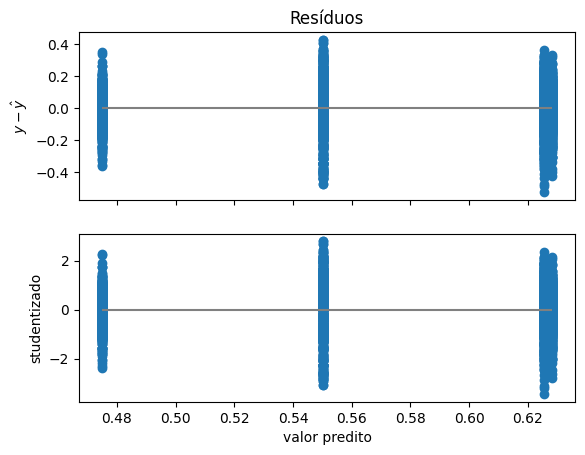

In [66]:
fig, (ax1, ax2) = plt.subplots(2)
ax1.scatter(ypred, res)
ax1.set_ylabel('$y-\hat{y}$')
ax1.set_title('Resíduos')
ax1.hlines(0,xmin=min(ypred),xmax=max(ypred),color='gray')
ax2.scatter(ypred, res_stud)
ax2.set_ylabel('studentizado')
ax2.set_xlabel('valor predito')
ax2.hlines(0,xmin=min(ypred),xmax=max(ypred),color='gray')

for ax in fig.get_axes():
    ax.label_outer()

In [67]:
# Teste de normalidade dos resíduos
stats.shapiro(res)

ShapiroResult(statistic=0.9935351538936478, pvalue=1.6180994009906466e-08)

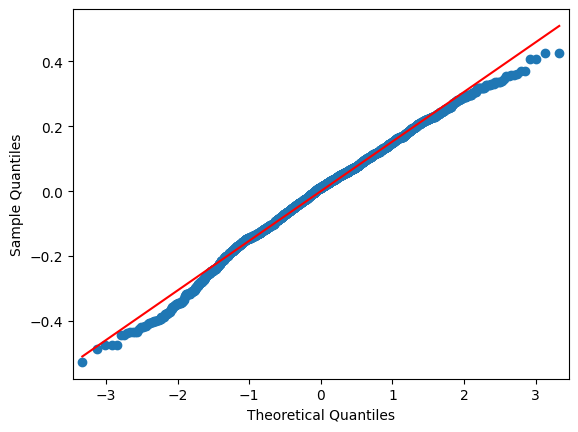

In [68]:
# Gráfico de probabilidade Normal
fig = sm.qqplot(res, line='s')

* ### **Teste t de Student pareado**

Dois métodos A e B de classificação geram resultados de acurácia (percentual de observações classificadas corretamente) para 8 diferentes conjuntos de dados. Os dados são:
metodo A = 85, 81, 89, 78, 80, 65, 93, 70
metodo B = 87, 84, 88, 80, 81, 62, 90, 76
Pode-se dizer que algum dos dois métodos tem maior acurácia, em média?

Inicialmente, vamos calcular as diferenças para os pares de valores e construir um boxplot para descrever os resultados.

{'whiskers': [<matplotlib.lines.Line2D at 0x7e4d61323d00>,
 'caps': [<matplotlib.lines.Line2D at 0x7e4d6135c280>,
 'boxes': [<matplotlib.lines.Line2D at 0x7e4d61323a60>],
 'medians': [<matplotlib.lines.Line2D at 0x7e4d6135c7c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7e4d6135ca60>],
 'means': []}

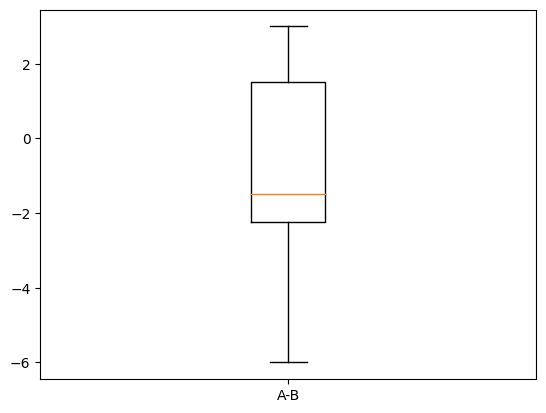

In [5]:
# Importando bibliotecas necessárias
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Dados fornecidos
metodo_a = np.array([85, 81, 89, 78, 80, 65, 93, 70])
metodo_b = np.array([87, 84, 88, 80, 81, 62, 90, 76])

# Calculando as diferenças pareadas
diferencas = metodo_a - metodo_b

# Descrevendo as diferenças pareadas
plt.boxplot(diferencas,labels=['A-B'])

Façamos o teste t de Student pareado, não esquecendo de verificar a suposição de normalidade dessas diferenças.

Estatística t: -0.8007
Valor-p: 0.4496


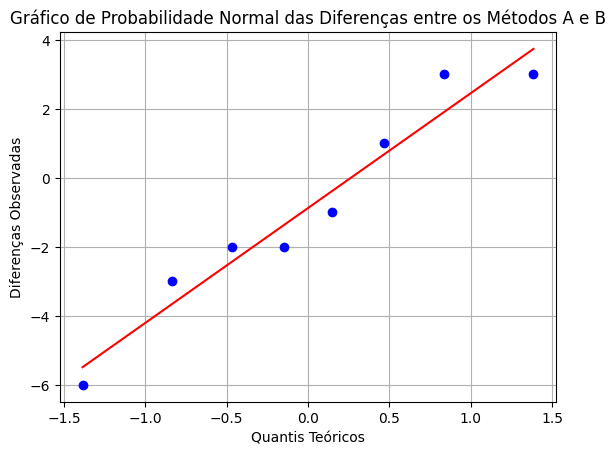

In [7]:
# Realizando o teste t pareado
t_stat, p_value = stats.ttest_rel(metodo_a, metodo_b)

# Exibindo os resultados do teste t
print(f"Estatística t: {t_stat:.4f}")
print(f"Valor-p: {p_value:.4f}")

# Gerando o gráfico de probabilidade normal
stats.probplot(diferencas, dist="norm", plot=plt)

# Personalizando o gráfico
plt.title("Gráfico de Probabilidade Normal das Diferenças entre os Métodos A e B")
plt.xlabel("Quantis Teóricos")
plt.ylabel("Diferenças Observadas")
plt.grid()

# Exibindo o gráfico
plt.show()


In [8]:
# Ou pelo teste para 1 população (equivalente à diferença média dos pares de valores igual a 0)
stats.ttest_1samp(metodo_a-metodo_b, 0)

TtestResult(statistic=-0.8007006277798856, pvalue=0.4496226328846836, df=7)

In [9]:
stat, p_value = stats.shapiro(diferencas)
print(f'Estatística do teste: {stat}')
print(f'Valor-p: {p_value}')

Estatística do teste: 0.939191732339163
Valor-p: 0.6031454134083168
